# sub-16 (jb): what was shown in its bars runs?

In `audit_checks.ipynb`, 3 of the 4 bars runs of sub-16 (RightEye Bars01 and Bars02, LeftEye Bars01) are predicted neither by the bars sequence of the model (A) nor by the old sequence (B), although its stimulus files announce B. jb is the first session of the study (1/07/2014, "Control02").

| test | question | reading |
|---|---|---|
| 0. Raw files | are `PARREC` and `PARRREC` identical? what do the PAR headers say for each series? do the BIDS series numbers match the mapping? | a series taken from the wrong folder, an unexpected protocol or number of volumes |
| 1. Signal | is there a visual response in these runs (amplitude, power at the stimulation frequencies, motion)? | flat signal = nothing seen (eye closed, occluder) |
| 2. Run × run similarity (no model) | which runs of sub-16 have the same time course in V1-V3? | suspect runs similar to each other = one unknown stimulus; similar to rings/wedges = label error; similar to nothing = no stimulation |
| 3. Stimulus reconstruction | project the activity of each TR onto the visual field using the pRFs estimated by the rings/wedges | a movie of what was displayed (bar position and direction, ring, wedge) |
| 4. Candidate library | which of all the stimulus files of `sourcedata` (deduplicated), in which orientation, time direction and delay, predicts the run best? | identifies the stimulus if it is a known one |

References: **sub-17** (bars version B, known) and **sub-13** (version A). Pixel size and pRFs as in the current fits (RingsWedges fit of each eye, independent of the bars). Read only; figures in `Desktop/fig_od` (prefix `sub16_`). Run at the lab: about 5-10 min.

In [1]:
import os, glob, math, hashlib, itertools
import numpy as np, pandas as pd, nibabel as nb
import scipy.io as sio
import matplotlib.pyplot as plt

main = '/Users/uriel/disks/meso_shared/amblyo7T_prf'
pp = f'{main}/derivatives/pp_data'
fig_dir = '/Users/uriel/Desktop/fig_od'
os.makedirs(fig_dir, exist_ok=True)
target, refs = 'sub-16', ['sub-17', 'sub-13']
run_list = ['BarsLeftEye_run-01', 'BarsLeftEye_run-02', 'RingsLeftEye_run-01', 'WedgesLeftEye_run-01',
            'BarsRightEye_run-01', 'BarsRightEye_run-02', 'RingsRightEye_run-01', 'WedgesRightEye_run-01']
suspect = ['BarsRightEye_run-01', 'BarsRightEye_run-02', 'BarsLeftEye_run-01']
TR = 2.0

/var/folders/60/q71xm4hx45x3db5d6mzl8r4h0000gn/T/ipykernel_2449/3811590569.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import numpy as np, pandas as pd, nibabel as nb


## 0. Raw files of jb

In [2]:
jb = f'{main}/sourcedata/C/jb'
def md5(fn, chunk=2 ** 24):
    h = hashlib.md5()
    with open(fn, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

rows = []
for fn in sorted(glob.glob(f'{jb}/PARREC/*.PAR')):
    name = os.path.basename(fn)
    other = f'{jb}/PARRREC/{name}'
    hdr = {}
    with open(fn, errors='ignore') as f:
        for line in f:
            if line.startswith('.') and ':' in line:
                k, v = line[1:].split(':', 1)
                hdr[k.strip()] = v.strip()
    rec, rec2 = fn[:-4] + '.REC', other[:-4] + '.REC'
    rows.append({'file': name, 'protocol': hdr.get('Protocol name'), 'series': hdr.get('Acquisition nr'),
                 'dynamics': hdr.get('Max. number of dynamics'), 'slices': hdr.get('Max. number of slices/locations'),
                 'duration_s': hdr.get('Scan Duration [sec]'), 'TR_ms': hdr.get('Repetition time [ms]'),
                 'PAR_identical': os.path.isfile(other) and md5(fn) == md5(other),
                 'REC_identical': os.path.isfile(rec2) and md5(rec) == md5(rec2)})
par = pd.DataFrame(rows)
print(par.to_string(index=False))

# BIDS series numbers vs the mapping file
mapping = {l.split()[3].replace('_bold', ''): int(l.split()[1]) for l in open(f'{jb}/bids_mapping_verification.txt') if l[:1].isdigit()}
for r in run_list:
    js = pd.read_json(f'{main}/{target}/ses-01/func/{target}_ses-01_task-{r}_bold.json', typ='series')
    print(r, 'BIDS series', js.get('SeriesNumber'), '| mapping', mapping.get(f'task-{r}'))

                                                file                          protocol series dynamics slices duration_s    TR_ms  PAR_identical  REC_identical
     Control02_WIP_2D_GE_EPI_AP_33_166_SENSE_5_1.PAR     WIP 2D_GE_EPI_AP_33_166 SENSE      5        5     36         16 1998.986           True           True
     Control02_WIP_2D_GE_EPI_RL_33_166_SENSE_6_1.PAR     WIP 2D_GE_EPI_RL_33_166 SENSE      6        5     36         16 1998.986           True           True
    Control02_WIP_2D_PhCorr_RL_33_166_SENSE_18_1.PAR     WIP 2D_PhCorr_RL_33_166 SENSE     18       10     36         26 1998.986           True           True
     Control02_WIP_2D_PhCorr_RL_33_166_SENSE_7_1.PAR     WIP 2D_PhCorr_RL_33_166 SENSE      7       10     36         26 1998.986           True           True
            Control02_WIP_B0_Map_Pride_SENSE_4_1.PAR            WIP B0 Map Pride SENSE      4        1     40       62.3   23.302           True           True
         Control02_WIP_fMRI_RL_33_166_SE

## Load the single runs (psc, both hemispheres), ROIs and RingsWedges pRFs

In [3]:
def load_runs(s):
    data = {}
    for r in run_list:
        hs = []
        for h in ['L', 'R']:
            fn = f'{pp}/{s}/fsnative/func/fmriprep_dct_psc/{s}_ses-01_task-{r}_hemi-{h}_space-fsnative_fmriprep_dct_psc_bold.func.gii'
            d = np.vstack([a.data for a in nb.load(fn).darrays])
            hs.append(d if d.shape[0] == 120 else d.T)
        data[r] = np.hstack(hs)
    roi = np.concatenate([nb.load(glob.glob(f'{pp}/{s}/fsnative/rois/{s}_hemi-{h}_fmriprep_dct_*_rois-group-mmp.func.gii')[0]).darrays[0].data
                          for h in ['L', 'R']])
    prf = {}
    for eye in ['LeftEye', 'RightEye']:
        prf[eye] = np.hstack([np.vstack([a.data for a in nb.load(
            f'{pp}/{s}/fsnative/prfmodel/prf_derivatives/{s}_task-RingsWedges{eye}_hemi-{h}_fmriprep_dct_psc_concat_prf-css_deriv.func.gii').darrays])
            for h in ['L', 'R']])
    return data, roi, prf


S = {s: load_runs(s) for s in [target] + refs}
for s, (data, roi, prf) in S.items():
    print(s, {r: d.shape for r, d in list(data.items())[:1]}, 'V1-V3 vertices:', int(((roi >= 1) & (roi <= 3)).sum()))


def good_vertices(s, eye, rsq=0.25, max_ecc=5.5, n_max=3000):
    data, roi, prf = S[s]
    D = prf[eye]
    ok = (roi >= 1) & (roi <= 3) & (D[0] > rsq) & (D[1] < max_ecc) & np.all([np.isfinite(d).all(0) for d in data.values()], axis=0)
    idx = np.where(ok)[0]
    if len(idx) > n_max:
        idx = np.sort(np.random.default_rng(0).choice(idx, n_max, replace=False))
    return idx

sub-16 {'BarsLeftEye_run-01': (120, 288560)} V1-V3 vertices: 31203
sub-17 {'BarsLeftEye_run-01': (120, 276395)} V1-V3 vertices: 23478
sub-13 {'BarsLeftEye_run-01': (120, 248185)} V1-V3 vertices: 24476


## 1. Is there a visual response in each run?

Per run, over the V1-V3 vertices well fitted by the rings/wedges: median temporal SD (% signal), fraction of the power of the mean V1-V3 time course at the rings/wedges frequency (1/24 s, 10 cycles per run) and at the bars frequencies, and mean framewise displacement.

In [4]:
def fd(s, r):
    fn = glob.glob(f'{main}/derivatives/fmriprep/fmriprep/{s}/ses-01/func/{s}_ses-01_task-{r}_desc-confounds_timeseries.tsv')
    return pd.read_csv(fn[0], sep='\t').framewise_displacement.mean() if fn else np.nan

rows = []
for s in [target] + refs:
    data, roi, prf = S[s]
    for r in run_list:
        eye = 'LeftEye' if 'LeftEye' in r else 'RightEye'
        idx = good_vertices(s, eye)
        y = data[r][:, idx]
        m = y.mean(1) - y.mean()
        p = np.abs(np.fft.rfft(m)) ** 2
        f = np.fft.rfftfreq(120, TR)
        p_rw = p[np.argmin(np.abs(f - 1 / 24))] / p[1:].sum()
        rows.append({'subject': s, 'run': r, 'n_vert': len(idx), 'sd_psc': np.median(y.std(0)),
                     'power_at_1/24Hz': p_rw, 'peak_freq_Hz': f[1:][np.argmax(p[1:])], 'fd_mean': fd(s, r),
                     'suspect': s == target and r in suspect})
sig = pd.DataFrame(rows)
sig.round(3)

,subject,run,n_vert,sd_psc,power_at_1/24Hz,peak_freq_Hz,fd_mean,suspect
0,sub-16,BarsLeftEye_run-01,3000,1.444,0.040,0.012,0.131,True
1,sub-16,BarsLeftEye_run-02,3000,1.476,0.053,0.038,0.159,False
2,sub-16,RingsLeftEye_run-01,3000,1.707,0.863,0.042,0.106,False
3,sub-16,WedgesLeftEye_run-01,3000,1.572,0.101,0.083,0.113,False
4,sub-16,BarsRightEye_run-01,3000,1.484,0.033,0.046,0.119,True
5,sub-16,BarsRightEye_run-02,3000,1.541,0.018,0.025,0.146,True
6,sub-16,RingsRightEye_run-01,3000,1.637,0.655,0.042,0.048,False
7,sub-16,WedgesRightEye_run-01,3000,1.512,0.141,0.042,0.078,False
8,sub-17,BarsLeftEye_run-01,3000,1.645,0.649,0.042,0.140,False
9,sub-17,BarsLeftEye_run-02,3000,1.287,0.483,0.042,0.140,False


## 2. Run × run similarity, no model

For each pair of runs of the same subject, median over vertices (V1-V3, good pRF in both eyes) of the correlation between their time courses. Runs with the same stimulus correlate (Bars01 ↔ Bars02 of one eye, and the same stimulus across eyes); runs with different stimuli do not.

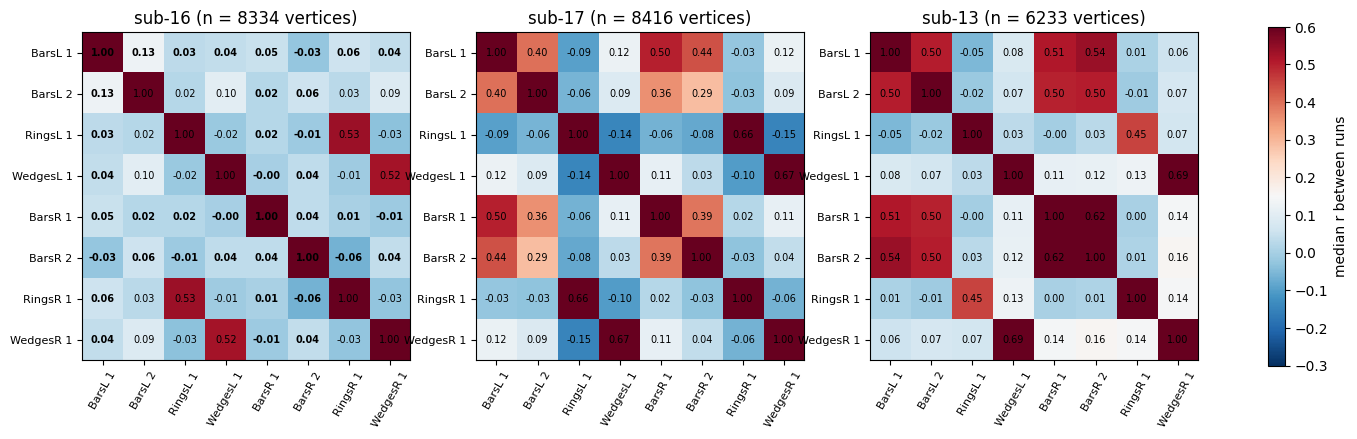

                       BarsLeftEye_run-01  BarsLeftEye_run-02  RingsLeftEye_run-01  WedgesLeftEye_run-01  BarsRightEye_run-01  BarsRightEye_run-02  RingsRightEye_run-01  WedgesRightEye_run-01
BarsLeftEye_run-01                   1.00                0.13                 0.03                  0.04                 0.05                -0.03                  0.06                   0.04
BarsLeftEye_run-02                   0.13                1.00                 0.02                  0.10                 0.02                 0.06                  0.03                   0.09
RingsLeftEye_run-01                  0.03                0.02                 1.00                 -0.02                 0.02                -0.01                  0.53                  -0.03
WedgesLeftEye_run-01                 0.04                0.10                -0.02                  1.00                -0.00                 0.04                 -0.01                   0.52
BarsRightEye_run-01                  0.0

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
sim = {}
for ax, s in zip(axes, [target] + refs):
    data, roi, prf = S[s]
    idx = np.intersect1d(good_vertices(s, 'LeftEye', n_max=10 ** 6), good_vertices(s, 'RightEye', n_max=10 ** 6))
    Z = {r: (data[r][:, idx] - data[r][:, idx].mean(0)) / (data[r][:, idx].std(0) + 1e-9) for r in run_list}
    M = np.array([[np.median((Z[a] * Z[b]).mean(0)) for b in run_list] for a in run_list])
    sim[s] = pd.DataFrame(M, index=run_list, columns=run_list)
    im = ax.imshow(M, vmin=-0.3, vmax=0.6, cmap='RdBu_r')
    for i in range(8):
        for j in range(8):
            ax.text(j, i, '{:.2f}'.format(M[i, j]), ha='center', va='center', fontsize=7,
                    fontweight='bold' if (s == target and (run_list[i] in suspect or run_list[j] in suspect)) else 'normal')
    lab = [r.replace('Eye_run-0', ' ').replace('Left', 'L').replace('Right', 'R') for r in run_list]
    ax.set_xticks(range(8)); ax.set_xticklabels(lab, rotation=60, fontsize=8)
    ax.set_yticks(range(8)); ax.set_yticklabels(lab, fontsize=8)
    ax.set_title('{} (n = {} vertices)'.format(s, len(idx)))
plt.colorbar(im, ax=axes, shrink=0.8, label='median r between runs')
fig.savefig(f'{fig_dir}/sub16_runs_similarity.pdf', bbox_inches='tight')
plt.show()
print(sim[target].round(2).to_string())

## Stimulus library (for tests 3 and 4)

All `cond-*-stim-*.mat` files of `sourcedata`, converted exactly as `create_vdm_files.ipynb` (50 × 50, transposed, padded), deduplicated by content and labelled by type (correlation with the model's bars, rings and wedges).

In [6]:
def build_vdm(mat_fn):
    im = np.asarray(sio.loadmat(mat_fn, squeeze_me=True, struct_as_record=False)['s'].im, float)
    out = np.zeros((50, 50, im.shape[-1]))
    ii = np.floor(np.arange(50) * 102 / 50).astype(int)
    for t in range(im.shape[-1]):
        f = (im[..., t] * 255).astype(np.uint8).T
        sq = np.vstack([np.zeros((12, 102), np.uint8), f, np.zeros((13, 102), np.uint8)])
        out[..., t] = (sq > 5)[np.ix_(ii, ii)]
    return out

model = np.load(f'{main}/derivatives/vdm/task-BarsBarsRingsWedgesLeftEye_vdm.npy')
ref_seg = {'bars_A': model[..., :120], 'rings': model[..., 240:360], 'wedges': model[..., 360:480]}

lib, seen = {}, {}
for fn in sorted(glob.glob(f'{main}/sourcedata/*/*/cond-*-stim-*.mat')):
    try:
        v = build_vdm(fn)
    except Exception as e:
        print('skip', fn, e); continue
    if v.shape[-1] != 120:
        print('skip (not 120 frames)', fn, v.shape); continue
    key = hashlib.md5(v.astype(np.uint8).tobytes()).hexdigest()
    src = '/'.join(fn.split('/')[-3:])
    if key in seen:
        seen[key].append(src); continue
    rs = {k: np.corrcoef(v.ravel(), r.ravel())[0, 1] for k, r in ref_seg.items()}
    for op_name, op in [('', lambda a: a), ('flipUD', lambda a: a[::-1]), ('flipLR', lambda a: a[:, ::-1])]:
        for k, r in ref_seg.items():
            rs[f'{k}{op_name}'] = np.corrcoef(op(v).ravel(), r.ravel())[0, 1]
    seen[key] = [src]
    lib[key] = {'vdm': v, 'first_file': src, 'best_match': max(rs, key=rs.get), 'r': max(rs.values())}
uniq = pd.DataFrame([{'key': k[:8], 'first_file': d['first_file'], 'n_files': len(seen[k]), 'closest_model': d['best_match'],
                      'r': d['r']} for k, d in lib.items()])
print(uniq.sort_values('closest_model').round(3).to_string(index=False))

skip (not 120 frames) /Users/uriel/disks/meso_shared/amblyo7T_prf/sourcedata/C/ez/cond-1-stim-3.mat (50, 50, 109)
skip (not 120 frames) /Users/uriel/disks/meso_shared/amblyo7T_prf/sourcedata/C/ez/cond-2-stim-3.mat (50, 50, 109)
     key             first_file  n_files closest_model     r
1870037e A/bm/cond-1-stim-2.mat       47        bars_A 0.999
7ee5d75a A/sm/cond-2-stim-1.mat       14        bars_A 0.185
9cddefbc A/cg/cond-1-stim-2.mat       24  bars_AflipUD 0.941
c877a6d1 A/bm/cond-1-stim-3.mat       30         rings 0.998
05b01fe9 A/cg/cond-1-stim-1.mat       12         rings 0.999
46237d08 C/ez/cond-1-stim-2.mat        2         rings 0.909
5e895947 A/bm/cond-1-stim-1.mat       29        wedges 1.000
6433963a A/cg/cond-1-stim-3.mat       14  wedgesflipUD 0.989


## 3. Reconstructing the stimulus from the brain

For each TR t, the z-scored activity of each vertex at t + lag (lag 1 TR, the earlier peak found in `audit_checks`) is spread on the visual field with the vertex pRF (Gaussian, RingsWedges fit), and normalised by the pRF coverage. Frames every 8 s for each bars run of sub-16, next to the bars of the model (A) and the old sequence (B), and to a reference run of sub-17 (B) and sub-13 (A).

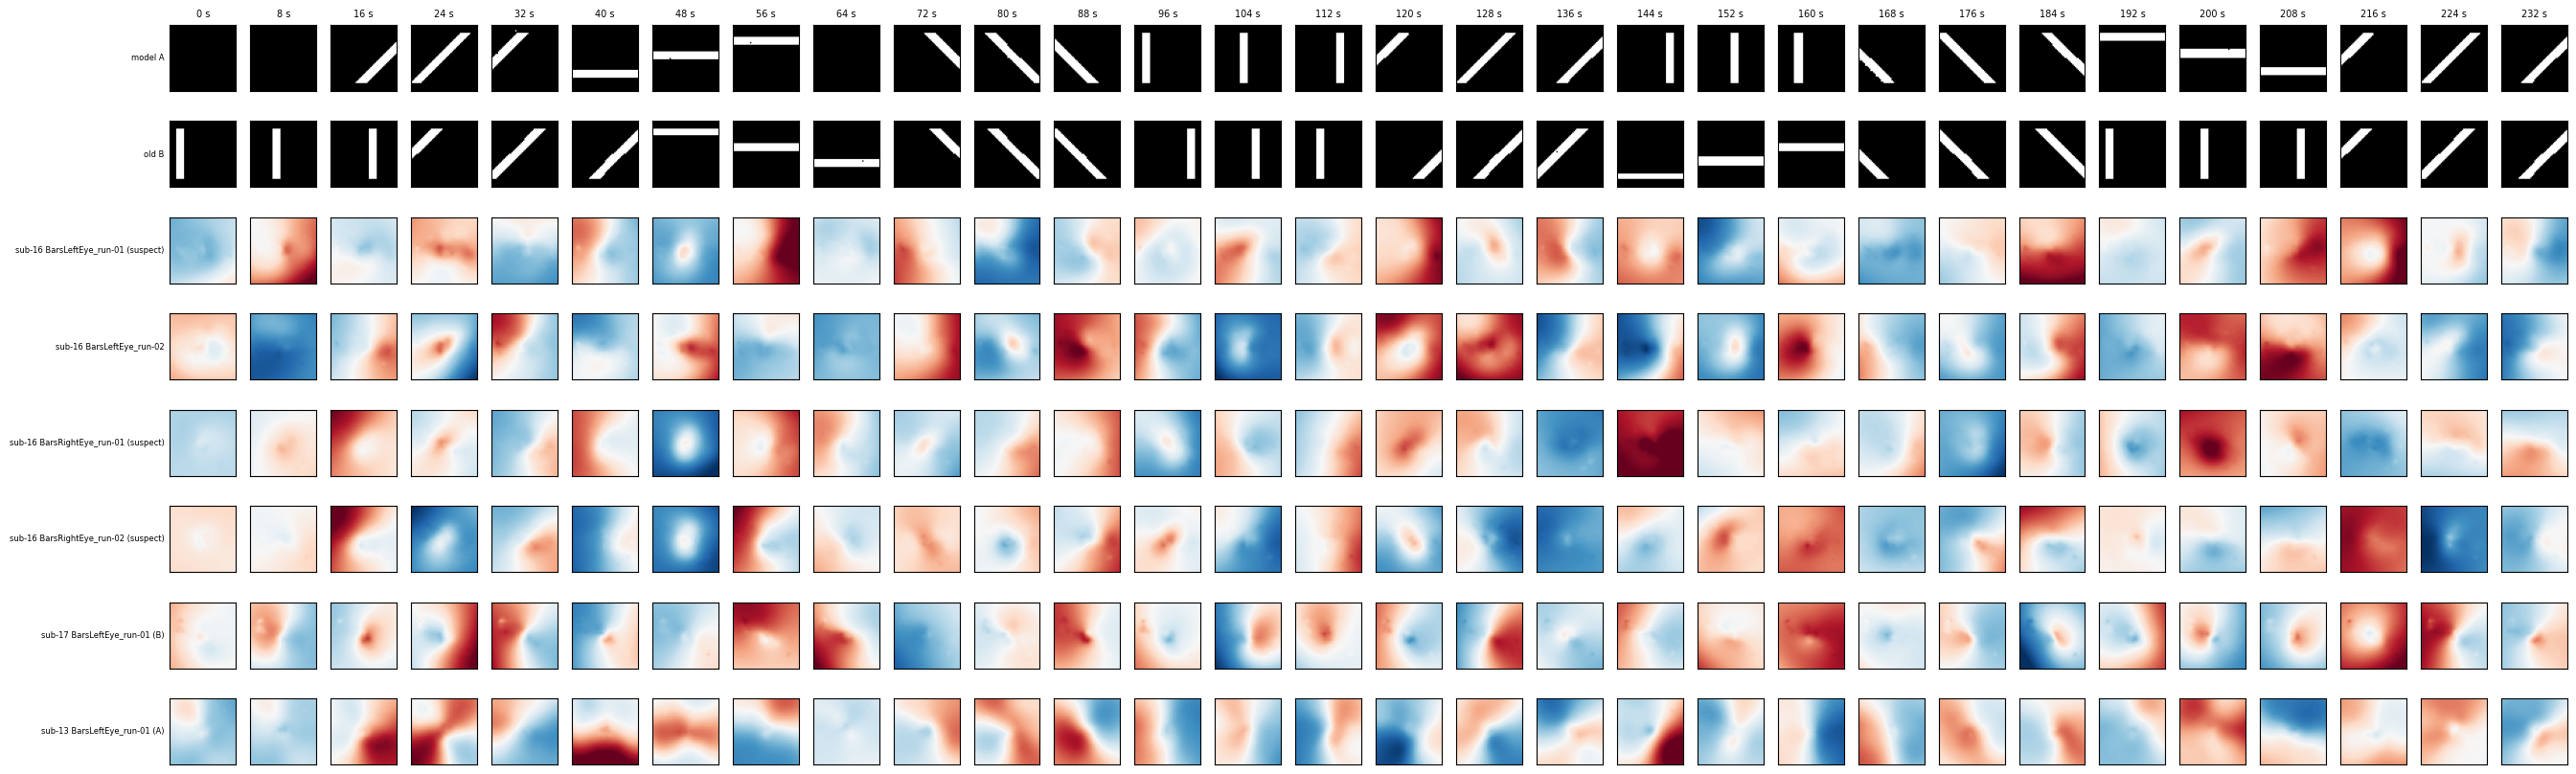

KeyError: 'closest_model'

In [7]:
pix = 2 * math.degrees(math.atan(50.6 / 2 / 242)) / 50          # current fits' convention
cc = (np.arange(50) - 24.5) * pix
X, Y = np.meshgrid(cc, -cc)
lag = 1


def gauss_maps(x0, y0, s):
    return np.exp(-((X.ravel()[:, None] - x0) ** 2 + (Y.ravel()[:, None] - y0) ** 2) / (2 * s ** 2))   # (2500, n)


def reconstruct(s, r):
    data, roi, prf = S[s]
    eye = 'LeftEye' if 'LeftEye' in r else 'RightEye'
    idx = good_vertices(s, eye, n_max=6000)
    D = prf[eye]
    G = gauss_maps(D[7][idx], D[8][idx], np.clip(D[4][idx], 0.2, None))
    y = data[r][:, idx]
    y = (y - y.mean(0)) / (y.std(0) + 1e-9)
    y = np.vstack([y[lag:], np.zeros((lag, y.shape[1]))])
    rec = (G @ y.T) / (G.sum(1, keepdims=True) + 1e-9)            # (2500, 120)
    return rec.reshape(50, 50, 120)


B = lib[[k for k, d in lib.items() if 'jp/cond-1-stim-3' in ' '.join(seen[k])][0]]['vdm'] if any('jp/cond-1-stim-3' in ' '.join(v) for v in seen.values()) else None
rows_show = [('model A', ref_seg['bars_A']), ('old B', B)]
for r in ['BarsLeftEye_run-01', 'BarsLeftEye_run-02', 'BarsRightEye_run-01', 'BarsRightEye_run-02']:
    rows_show.append((f'{target} {r}' + (' (suspect)' if r in suspect else ''), reconstruct(target, r)))
rows_show.append(('sub-17 BarsLeftEye_run-01 (B)', reconstruct('sub-17', 'BarsLeftEye_run-01')))
rows_show.append(('sub-13 BarsLeftEye_run-01 (A)', reconstruct('sub-13', 'BarsLeftEye_run-01')))
frames = list(range(0, 120, 4))
fig, axes = plt.subplots(len(rows_show), len(frames), figsize=(len(frames) * 0.9, len(rows_show) * 1.05))
for i, (name, mov) in enumerate(rows_show):
    for j, t in enumerate(frames):
        ax = axes[i, j]
        if mov is not None:
            fr = mov[..., t]
            lim = np.nanpercentile(np.abs(mov), 99) if 'model' not in name and 'old' not in name else 1
            ax.imshow(fr, cmap='gray' if lim == 1 else 'RdBu_r', vmin=-lim if lim != 1 else 0, vmax=lim)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title('{} s'.format(int(t * TR)), fontsize=7)
        if j == 0: ax.set_ylabel(name, fontsize=6, rotation=0, ha='right', va='center')
plt.tight_layout()
fig.savefig(f'{fig_dir}/sub16_stimulus_reconstruction.pdf', bbox_inches='tight')
plt.show()

# Quantitative: correlation of each reconstructed movie with each stimulus of the library (and A, B), per run
def movie_corr(rec, stim):
    a = rec.reshape(-1, 120); b = stim.reshape(-1, 120)
    m = b.std(1) > 0                                               # pixels stimulated at least once
    a = a[m] - a[m].mean(1, keepdims=True); b = b[m] - b[m].mean(1, keepdims=True)
    return float(np.sum(a * b) / np.sqrt(np.sum(a ** 2) * np.sum(b ** 2)))

rows = []
for s, r in [(target, x) for x in run_list] + [('sub-17', 'BarsLeftEye_run-01'), ('sub-13', 'BarsLeftEye_run-01')]:
    rec = reconstruct(s, r)
    res = {'subject': s, 'run': r}
    for k, d in lib.items():
        res['{} ({})'.format(d['closest_model'], k[:4])] = movie_corr(rec, d['vdm'])
    rows.append(res)
recon = pd.DataFrame(rows).set_index(['subject', 'run'])
print('Correlation between the reconstructed movie and each stimulus of the library:')
print(recon.round(2).to_string())

## 4. Candidate library: prediction of each run

For each run: prediction = canonical HRF * (stimulus · Gaussian pRF)^n (RingsWedges pRFs of the same eye), for every stimulus of the library × {as is, time-reversed, flipped up/down, flipped left/right, rotated 90°} × delays of −3 to +3 TR. Median correlation over V1-V3 vertices; top 5 candidates per run. Validation: the reference runs (sub-17: B, sub-13: A) and the rings/wedges runs of sub-16 must find their own stimulus.

In [8]:
t_ = np.arange(0, 32, TR)
g = lambda a: t_ ** (a - 1) * np.exp(-t_) / math.gamma(a)
H = g(6) - g(16) / 6; H /= H.sum()
Hf = np.fft.rfft(np.r_[H, np.zeros(120 + len(H))])


def conv_hrf(d):
    n = d.shape[0]
    return np.fft.irfft(np.fft.rfft(np.vstack([d, np.zeros((len(H) + 120, d.shape[1]))]), axis=0) * Hf[:, None], axis=0)[:n]


transforms = {'': lambda a: a, 'rev': lambda a: a[..., ::-1], 'UD': lambda a: a[::-1], 'LR': lambda a: a[:, ::-1],
              'rot90': lambda a: np.rot90(a, 1, axes=(0, 1))}
cands = {}
for k, d in lib.items():
    for tn, op in transforms.items():
        cands['{}:{}{}'.format(d['closest_model'], k[:4], ('/' + tn) if tn else '')] = op(d['vdm'])


def zc(a):
    a = a - a.mean(0)
    return a / (a.std(0) + 1e-9)


def score_run(s, r, n_max=2000):
    data, roi, prf = S[s]
    eye = 'LeftEye' if 'LeftEye' in r else 'RightEye'
    idx = good_vertices(s, eye, n_max=n_max)
    D = prf[eye]
    G = gauss_maps(D[7][idx], D[8][idx], np.clip(D[4][idx], 0.1, None))
    n = np.clip(D[11][idx], 0.05, 1)
    y = zc(data[r][:, idx])
    out = {}
    for name, stim in cands.items():
        p = conv_hrf((stim.reshape(-1, 120).T @ G) ** n)
        for sh in range(-3, 4):
            q = np.roll(p, sh, 0)
            if sh > 0: q[:sh] = p[0]
            elif sh < 0: q[sh:] = p[-1]
            out[f'{name} {sh:+d}TR'] = float(np.median((zc(q) * y).mean(0)))
    return pd.Series(out).sort_values(ascending=False)


results = {}
for s, r in [(target, x) for x in run_list] + [('sub-17', 'BarsLeftEye_run-01'), ('sub-13', 'BarsLeftEye_run-01')]:
    sc = score_run(s, r)
    results[(s, r)] = sc
    print('\n{} {}{}'.format(s, r, '  <-- suspect' if (s == target and r in suspect) else ''))
    print(sc.head(5).round(3).to_string())

KeyError: 'closest_model'

## Summary

In [9]:
rows = []
for (s, r), sc in results.items():
    rows.append({'subject': s, 'run': r, 'suspect': s == target and r in suspect, 'best candidate': sc.index[0], 'r best': sc.iloc[0],
                 'r 2nd': sc.iloc[1], 'r model bars A (best delay)': sc[[i for i in sc.index if i.startswith('bars_A:') and '/' not in i]].max()
                 if 'Bars' in r else np.nan})
summ = pd.DataFrame(rows)
print(summ.round(3).to_string(index=False))
print("Reading:")
print("- suspect runs with a clear best candidate (r close to the good bars runs, ~0.4-0.6): that stimulus was shown -> build its design matrix and keep the runs;")
print("- suspect runs best predicted by a rings/wedges candidate, and similar to a rings/wedges run in test 2: label error;")
print("- suspect runs with low r for every candidate, low power and no structure in the reconstruction (test 3): no effective stimulation -> exclude them (criterion documented by tests 1-3).")

NameError: name 'results' is not defined